# Setup

## Installs

In [1]:
!pip -q install transformers pycocoevalcap inflect ftfy regex
!pip -q install git+https://github.com/openai/CLIP.git
!apt-get -qq update > /dev/null && apt-get -qq install -y default-jre > /dev/null

!java -version
!nvidia-smi --query-gpu=name,memory.total --format=csv
!df -h /content

!test -d /content/CLIP_prefix_caption || git clone -q https://github.com/rmokady/CLIP_prefix_caption /content/CLIP_prefix_caption

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[0.018s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.018s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
name, memory.total [MiB]
Tesla T4, 15360 MiB
Filesystem      Size  Used Avail Use% Mounted on
o

## Imports

In [11]:
import os
import io
import sys
import json
import pickle
import shutil
import zipfile
import subprocess
from collections import Counter

import nltk
import torch
import clip
import gdown
import transformers
import matplotlib.pyplot as plt
import inflect
import warnings
import logging
import numpy as np
import random

from pycocoevalcap.tokenizer.ptbtokenizer import PTBTokenizer
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.meteor.meteor import Meteor
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.spice.spice import Spice

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import GPT2Tokenizer
from google.colab import drive

# ClipCap's train.py imports AdamW from transformers, removed in newer versions
transformers.AdamW = torch.optim.AdamW
sys.path.append('/content/CLIP_prefix_caption')
from train import ClipCaptionPrefix, MappingType

warnings.filterwarnings('ignore')
logging.getLogger('huggingface_hub').setLevel(logging.ERROR)

# stop Java warnings from corrupting pycocoevalcap output (tokenizer, METEOR)
os.environ['JAVA_TOOL_OPTIONS'] = '-Xlog:disable'

## NLTK Data

In [3]:
for pkg in ['punkt', 'punkt_tab', 'wordnet', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

## Mount GDrive

In [39]:
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/sc4001_nndl_grp_project/phase_1/track_1'
print(os.listdir(ROOT))

DATA_DIR = os.path.join(ROOT, 'data')
FEAT_DIR = os.path.join(ROOT, 'features')
EVAL_DIR = os.path.join(ROOT, 'eval')
RESULTS_DIR = os.path.join(ROOT, 'results')
MODELS_DIR = os.path.join(ROOT, 'models')
IMG_DRIVE = os.path.join(ROOT, 'images')  # image zips kept on Drive
LOCAL = '/content/coco'  # local disk, wiped each session

for d in [DATA_DIR, FEAT_DIR, EVAL_DIR, RESULTS_DIR, MODELS_DIR, IMG_DRIVE, LOCAL]:
    os.makedirs(d, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data', 'features', 'eval', 'results', 'models', 'images', 'track_1.ipynb']


# Annotations & Karpathy Split

## Helper Functions

In [25]:
def download(url, out_dir):
    subprocess.run(['wget', '-c', '-q', '--show-progress', '-P', out_dir, url], check=True)
    return os.path.join(out_dir, os.path.basename(url))


def extract_members(zip_path, names, out_dir):
    # copy selected files out of a zip, tmp then rename so no half files
    with zipfile.ZipFile(zip_path) as z:
        lookup = {}
        for member in z.namelist():
            lookup[os.path.basename(member)] = member
        for name in names:
            dst = os.path.join(out_dir, name)
            with z.open(lookup[name]) as src, open(dst + '.tmp', 'wb') as out:
                shutil.copyfileobj(src, out)
            os.replace(dst + '.tmp', dst)


def norm_split(s):
    # restval counts as train
    if s in ('train', 'restval'):
        return 'train'
    else:
        return s

## Download

In [ ]:
ANN_FILES = ['captions_train2014.json', 'captions_val2014.json', 'instances_train2014.json', 'instances_val2014.json']

ann_missing = False
for f in ANN_FILES:
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        ann_missing = True

if ann_missing:
    zp = download('http://images.cocodataset.org/annotations/annotations_trainval2014.zip', LOCAL)
    extract_members(zp, ANN_FILES, DATA_DIR)

if not os.path.exists(os.path.join(DATA_DIR, 'dataset_coco.json')):
    zp = download('https://cs.stanford.edu/people/karpathy/deepimagesent/caption_datasets.zip', LOCAL)
    extract_members(zp, ['dataset_coco.json'], DATA_DIR)

for f in ANN_FILES + ['dataset_coco.json']:
    size_mb = os.path.getsize(os.path.join(DATA_DIR, f)) / 1e6
    print(f, round(size_mb, 1), 'MB')

captions_train2014.json 66.8 MB
captions_val2014.json 32.4 MB
instances_train2014.json 332.6 MB
instances_val2014.json 160.7 MB
dataset_coco.json 144.2 MB


## Verify

In [ ]:
with open(os.path.join(DATA_DIR, 'dataset_coco.json')) as fh:
    kp = json.load(fh)['images']

raw_counts = Counter()
split_counts = Counter()
kp_ids = set()
for im in kp:
    raw_counts[im['split']] += 1
    split = norm_split(im['split'])
    split_counts[split] += 1
    kp_ids.add(im['cocoid'])
    # Karpathy val and test must come from val2014
    if split != 'train':
        assert im['filepath'] == 'val2014', im['cocoid']

print('raw splits:', raw_counts)
print('merged splits:', split_counts)
assert split_counts['train'] == 113287, split_counts
assert split_counts['val'] == 5000, split_counts
assert split_counts['test'] == 5000, split_counts
assert len(kp_ids) == len(kp), 'duplicate image ids'

raw splits: Counter({'train': 82783, 'restval': 30504, 'test': 5000, 'val': 5000})
merged splits: Counter({'train': 113287, 'test': 5000, 'val': 5000})


In [ ]:
# Check every Karpathy id exists in instances JSON
inst_ids = set()
for f in ['instances_train2014.json', 'instances_val2014.json']:
    with open(os.path.join(DATA_DIR, f)) as fh:
        images = json.load(fh)['images']
    for im in images:
        inst_ids.add(im['id'])
    del images

missing = kp_ids - inst_ids
print('missing from instances:', len(missing))
assert len(missing) == 0
del inst_ids

missing from instances: 0


## Build Index

In [ ]:
cap_counts = Counter()
index = []

for im in kp:
    captions = []
    for s in im['sentences']:
        captions.append(s['raw'].strip())

    cap_counts[len(captions)] += 1

    index.append({
        'image_id': im['cocoid'],
        'member': im['filepath'] + '/' + im['filename'],
        'split': norm_split(im['split']),
        'captions': captions
    })

index.sort(key=lambda r: r['image_id'])

print('captions per image:', cap_counts)

with open(os.path.join(DATA_DIR, 'karpathy_index.json'), 'w') as fh:
    json.dump(index, fh)

print('saved index:', len(index), 'images')

captions per image: Counter({5: 122959, 6: 324, 7: 4})
saved index: 123287 images


# Image Download

## Helper Functions

In [27]:
def copy_atomic(src, dst):
    # copy via tmp file so a disconnect never leaves a half file
    shutil.copy(src, dst + '.tmp')
    os.replace(dst + '.tmp', dst)

## Get zip to local disk

In [ ]:
KEEP_ON_DRIVE = {'train2014.zip', 'val2014.zip'}
EXPECTED = {'train2014.zip': 82783, 'val2014.zip': 40504}
ZIPS = {}

for name in EXPECTED:
    n_expected = EXPECTED[name]
    local_zp = os.path.join(LOCAL, name)
    drive_zp = os.path.join(IMG_DRIVE, name)

    # use Drive copy if saved before
    if not os.path.exists(local_zp) and os.path.exists(drive_zp):
        print('copying from Drive:', name)
        copy_atomic(drive_zp, local_zp)

    # resumes partial download if not completed
    zp = download('http://images.cocodataset.org/zips/' + name, LOCAL)

    # verify image count
    n_jpg = 0

    with zipfile.ZipFile(zp) as z:
        for member in z.namelist():
            if member.endswith('.jpg'):
                n_jpg += 1

    size_gb = os.path.getsize(zp) / 1e9
    print(name, round(size_gb, 2), 'GB,', n_jpg, 'images')
    assert n_jpg == n_expected, name

    # save verified zip to drive
    if name in KEEP_ON_DRIVE and not os.path.exists(drive_zp):
        print('saving to Drive:', name)
        copy_atomic(zp, drive_zp)

    ZIPS[name.replace('.zip', '')] = zp

# check local disk space after downloads
total, used, free = shutil.disk_usage('/content')
print('local disk free:', round(free / 1e9, 1), 'GB')

copying from Drive: train2014.zip
train2014.zip 13.51 GB, 82783 images
val2014.zip 6.65 GB, 40504 images
saving to Drive: val2014.zip
local disk free: 48.2 GB


# Feature Extraction

## Load CLIP RN50x4

In [ ]:
if 'index' not in globals():
    with open(os.path.join(DATA_DIR, 'karpathy_index.json')) as fh:
        index = json.load(fh)

device = 'cuda'
# stop early if no GPU is attached
assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU'
print('using:', torch.cuda.get_device_name(0))

clip_model, preprocess = clip.load('RN50x4', device=device, jit=False)
_ = clip_model.eval()

using: Tesla T4


## Read images from zips

In [ ]:
class ZipImages(Dataset):
    # one set of zip handles per worker
    def __init__(self, rows):
        self.rows = rows
        self.handles = None

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        if self.handles is None:
            self.handles = {}

            for key in ZIPS:
                self.handles[key] = zipfile.ZipFile(ZIPS[key])

        r = self.rows[i]
        folder = r['member'].split('/')[0]
        z = self.handles[folder]
        img = Image.open(io.BytesIO(z.read(r['member']))).convert('RGB')
        return preprocess(img), r['image_id']

## Sharded extraction

In [ ]:
SHARD_SIZE = 5000
BATCH_SIZE = 125  # divides SHARD_SIZE, so a batch never spans two shards
SHARD_DIR = os.path.join(FEAT_DIR, 'rn50x4_shards')
os.makedirs(SHARD_DIR, exist_ok=True)

# one worker per CPU core
n_workers = os.cpu_count()
print('cpu cores:', n_workers)

shards = []
for start in range(0, len(index), SHARD_SIZE):
    shards.append(index[start:start + SHARD_SIZE])


def shard_path(k):
    return os.path.join(SHARD_DIR, f'shard_{k:03d}.pt')


# skip shards finished in an earlier session
pending = []
pending_rows = []
n_already = 0

for k in range(len(shards)):
    if os.path.exists(shard_path(k)):
        n_already += 1
    else:
        pending.append(k)
        pending_rows.extend(shards[k])

print('shards already done:', n_already, 'of', len(shards))
print('shards to do:', len(pending), 'of', len(shards))

if len(pending) > 0:
    # one loader for all pending shards, avoids worker cleanup warnings
    loader = DataLoader(ZipImages(pending_rows), batch_size=BATCH_SIZE, num_workers=n_workers, pin_memory=True)
    pos = 0
    feats = []
    ids = []
    n_in_shard = 0

    with torch.no_grad():
        for x, iid in tqdm(loader, desc='extracting'):
            emb = clip_model.encode_image(x.to(device))
            feats.append(emb.half().cpu())
            ids.append(iid)
            n_in_shard += len(iid)

            k = pending[pos]
            assert n_in_shard <= len(shards[k]), 'batch crossed a shard boundary'

            # shard complete: save to Drive, tmp then rename
            if n_in_shard == len(shards[k]):
                out = shard_path(k)
                torch.save({'image_ids': torch.cat(ids), 'features': torch.cat(feats)}, out + '.tmp')
                os.replace(out + '.tmp', out)
                feats = []
                ids = []
                n_in_shard = 0
                pos += 1

n_done = 0

for f in os.listdir(SHARD_DIR):
    if f.endswith('.pt'):
        n_done += 1

print('shards done:', n_done, 'of', len(shards))

cpu cores: 2
shards already done: 0 of 25
shards to do: 25 of 25


extracting:   0%|          | 0/987 [00:00<?, ?it/s]

shards done: 25 of 25


# Merge, Verify and Save Features

## Merge Shards

In [ ]:
# load image index from Drive if not in memory
if 'index' not in globals():
    print('loading image index...')

    with open(os.path.join(DATA_DIR, 'karpathy_index.json')) as fh:
        index = json.load(fh)

print('index loaded:', len(index), 'images')

SHARD_SIZE = 5000
SHARD_DIR = os.path.join(FEAT_DIR, 'rn50x4_shards')

# split index into chunks of 5000 to match the saved shards
shards = []
for start in range(0, len(index), SHARD_SIZE):
    shards.append(index[start:start + SHARD_SIZE])

# load every shard from Drive
id_parts = []
feat_parts = []

for k in tqdm(range(len(shards)), desc='loading shards'):
    part = torch.load(os.path.join(SHARD_DIR, f'shard_{k:03d}.pt'))
    id_parts.append(part['image_ids'])
    feat_parts.append(part['features'])

# join into one list of ids and one feature tensor
all_ids = torch.cat(id_parts).tolist()
all_feats = torch.cat(feat_parts)
print('merged:', len(all_ids), 'ids, features', tuple(all_feats.shape))

index loaded: 123287 images


loading shards:   0%|          | 0/25 [00:00<?, ?it/s]

merged: 123287 ids, features (123287, 640)


## Verify order, shape, NaNs

In [ ]:
expected_ids = []
for r in index:
    expected_ids.append(r['image_id'])

assert all_ids == expected_ids, 'id order mismatch'
print('id order: ok')

assert all_feats.shape == (len(index), 640), all_feats.shape
print('shape: ok', tuple(all_feats.shape))

assert torch.isfinite(all_feats.float()).all(), 'NaN or inf in features'
print('no NaN or inf: ok')

# feature lengths should all be similar and nonzero
norms = all_feats.float().norm(dim=-1)
print('norm min / mean / max:', round(norms.min().item(), 3),
      round(norms.mean().item(), 3), round(norms.max().item(), 3))

id order: ok
shape: ok (123287, 640)
no NaN or inf: ok
norm min / mean / max: 2.352 3.132 4.895


## Save ClipCap pkl files

In [ ]:
# map image id to its row in all_feats
row_of = {}

for i in range(len(all_ids)):
    row_of[all_ids[i]] = i

for split in ['train', 'val', 'test']:
    out = os.path.join(FEAT_DIR, f'coco_rn50x4_{split}.pkl')

    if os.path.exists(out):
        print(split, ': exists, skipping')
        continue

    print(split, ': building...')
    rows = []
    for r in index:

        if r['split'] == split:
            rows.append(r)

    # one embedding per image, captions point to their row
    feat_rows = []
    caps = []

    for j in range(len(rows)):
        r = rows[j]
        feat_rows.append(row_of[r['image_id']])

        for c in r['captions']:
            caps.append({'image_id': r['image_id'], 'caption': c, 'clip_embedding': j})

    emb = all_feats[feat_rows]

    # save to Drive
    print(split, ': saving to Drive...')
    with open(out + '.tmp', 'wb') as fh:
        pickle.dump({'clip_embedding': emb, 'captions': caps}, fh)

    os.replace(out + '.tmp', out)

    size_mb = os.path.getsize(out) / 1e6
    print(split, ': done', tuple(emb.shape), len(caps), 'captions,', round(size_mb, 1), 'MB')

train : building...
train : saving to Drive...
train : done (113287, 640) 566747 captions, 186.9 MB
val : building...
val : saving to Drive...
val : done (5000, 640) 25010 captions, 8.2 MB
test : building...
test : saving to Drive...
test : done (5000, 640) 25010 captions, 8.2 MB


# Test features on pretrained CLIPCAP

## Get val images

In [29]:
# only val images are needed, so fetch val2014 alone
VAL_ZIP = os.path.join(LOCAL, 'val2014.zip')

# use Drive copy if uploaded else download from COCO
drive_val = os.path.join(IMG_DRIVE, 'val2014.zip')
if os.path.exists(VAL_ZIP):
    print('val2014.zip already on local disk')
elif os.path.exists(drive_val):
    print('copying from Drive: val2014.zip')
    copy_atomic(drive_val, VAL_ZIP)
else:
    print('downloading from COCO: val2014.zip (a few minutes)')

# resumes partial download if not completed
download('http://images.cocodataset.org/zips/val2014.zip', LOCAL)

# verify image count
print('verifying...')
n_jpg = 0
with zipfile.ZipFile(VAL_ZIP) as z:
    for member in z.namelist():
        if member.endswith('.jpg'):
            n_jpg += 1

print('val2014.zip', round(os.path.getsize(VAL_ZIP) / 1e9, 2), 'GB,', n_jpg, 'images')
assert n_jpg == 40504

ZIPS = {'val2014': VAL_ZIP}
print('ready')

val2014.zip already on local disk
verifying...
val2014.zip 6.65 GB, 40504 images
ready


## Load pretrained checkpoint

In [30]:
# device and index may not exist if feature extraction has not been run
device = 'cuda'
assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU'
print('using:', torch.cuda.get_device_name(0))

if 'index' not in globals():
    with open(os.path.join(DATA_DIR, 'karpathy_index.json')) as fh:
        index = json.load(fh)
print('index loaded:', len(index), 'images')

CKPT_PATH = os.path.join(MODELS_DIR, 'clipcap_transformer_coco_pretrained.pt')

# download once to Drive
# file id from ClipCap README
if not os.path.exists(CKPT_PATH):
    print('downloading checkpoint (about 600 MB, first run only)...')
    gdown.download(id='1GYPToCqFREwi285wPLhuVExlz7DDUDfJ', output=CKPT_PATH + '.tmp', quiet=False)
    os.replace(CKPT_PATH + '.tmp', CKPT_PATH)
print('checkpoint:', round(os.path.getsize(CKPT_PATH) / 1e6, 1), 'MB')

PREFIX_LENGTH = 40
ckpt_model = ClipCaptionPrefix(PREFIX_LENGTH, clip_length=40, prefix_size=640, num_layers=8, mapping_type=MappingType.Transformer)

# newer transformers dropped GPT-2 attention buffers
# strict = False to ignore them
state = torch.load(CKPT_PATH, map_location='cpu')
result = ckpt_model.load_state_dict(state, strict=False)

assert len(result.missing_keys) == 0, result.missing_keys

# leading dot so real weights like c_attn.bias cannot slip through
for key in result.unexpected_keys:
    assert key.endswith('.attn.bias') or key.endswith('.attn.masked_bias'), key
print('missing keys: 0, stale buffers ignored:', len(result.unexpected_keys))

ckpt_model = ckpt_model.to(device)
_ = ckpt_model.eval()
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
print('model ready')

using: Tesla T4
index loaded: 123287 images
checkpoint: 740.5 MB


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

missing keys: 0, stale buffers ignored: 24
model ready


## Greedy decoder

### Helper Function

In [31]:
STOP_ID = tokenizer.encode('.')[0]
MAX_TOKENS = 30

def greedy_decode(model, feature):
    # feature is one raw 640-d CLIP vector
    prefix = feature.float().to(device).unsqueeze(0)

    # checkpoint expects L2-normalised input
    prefix = prefix / prefix.norm(dim=-1, keepdim=True)

    token_ids = []
    with torch.no_grad():
        embeds = model.clip_project(prefix).reshape(1, PREFIX_LENGTH, -1)

        for step in range(MAX_TOKENS):
            logits = model.gpt(inputs_embeds=embeds).logits[:, -1, :]
            next_id = logits.argmax(dim=-1)
            token_ids.append(next_id.item())

            if next_id.item() == STOP_ID:
                break

            next_embed = model.gpt.transformer.wte(next_id).unsqueeze(1)
            embeds = torch.cat((embeds, next_embed), dim=1)

    return tokenizer.decode(token_ids).strip()

### Compare captions on 10 val images

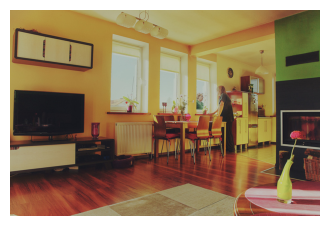

image: 139
pred:  A woman is standing in a kitchen with a table.
ground truth:  A woman stands in the dining area at the table.



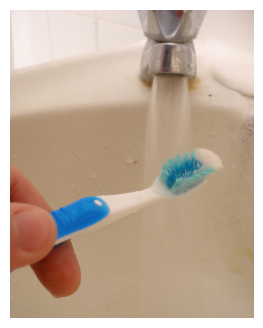

image: 58079
pred:  A person holding a blue toothbrush in a sink.
ground truth:  A person holding a toothbrush under the running water of a faucet.



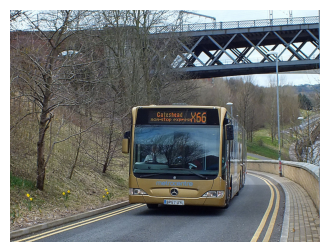

image: 119402
pred:  A bus driving down a road with a tower on top.
ground truth:  A gold bus traveling on a single lane road



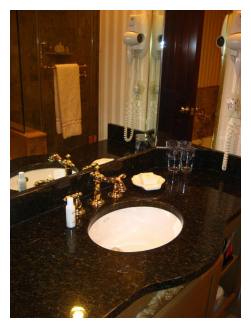

image: 178028
pred:  A bathroom with a sink and a mirror.
ground truth:  A bathroom vanity sink with a large mirror and hairdryer on the wall.



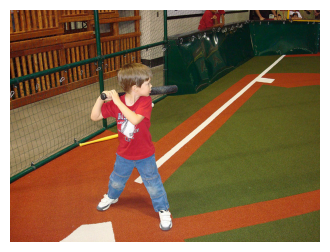

image: 232185
pred:  A young boy swinging a bat at a ball.
ground truth:  The small boy is ready at bat in the indoor batting cage.



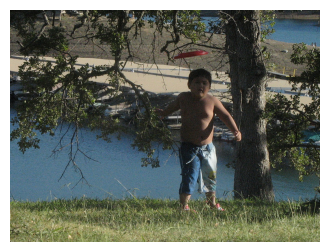

image: 290979
pred:  A little boy is playing with a toy.
ground truth:  Chubby little kid is making a face near a lake



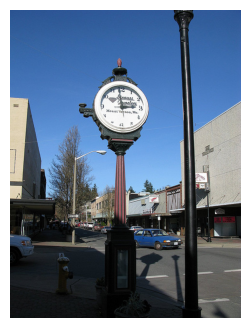

image: 349575
pred:  A clock on a pole near a city street.
ground truth:  A clock on a corner at a city intersection.



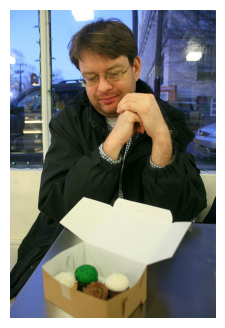

image: 408071
pred:  A man sitting at a table with a piece of paper.
ground truth:  A man sitting at a table looking at a box of cupcakes.



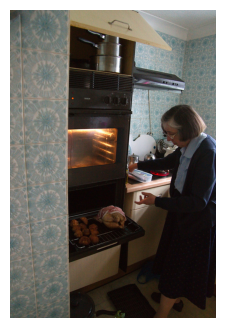

image: 467297
pred:  A woman is putting food into an oven.
ground truth:  a woman is standing next to an oven



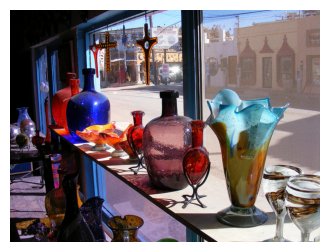

image: 526732
pred:  A bunch of vases sitting on a table.
ground truth:  A bunch of vases are arranged in a store window



In [32]:
with open(os.path.join(FEAT_DIR, 'coco_rn50x4_val.pkl'), 'rb') as fh:
    val_data = pickle.load(fh)

# map embedding row to image id and GT captions
row_image = {}
row_gts = {}
for cap in val_data['captions']:
    j = cap['clip_embedding']
    row_image[j] = cap['image_id']
    if j not in row_gts:
        row_gts[j] = []
    row_gts[j].append(cap['caption'])

member_of = {}
for r in index:
    member_of[r['image_id']] = r['member']

val_zip = zipfile.ZipFile(ZIPS['val2014'])

# 10 images spread across val, so they come from different shards
for j in range(0, 5000, 500):
    image_id = row_image[j]
    pred = greedy_decode(ckpt_model, val_data['clip_embedding'][j])
    img = Image.open(io.BytesIO(val_zip.read(member_of[image_id]))).convert('RGB')

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    print('image:', image_id)
    print('pred: ', pred)
    print('ground truth: ', row_gts[j][0])
    print()

val_zip.close()

# CHAIR and Object List

## Helper Functions

In [6]:
SYN_URL = 'https://raw.githubusercontent.com/LisaAnne/Hallucination/master/data/synonyms.txt'
SYN_PATH = os.path.join(EVAL_DIR, 'synonyms.txt')

# small text file downloaded once
if not os.path.exists(SYN_PATH):
    print('downloading synonyms.txt...')
    download(SYN_URL, EVAL_DIR)

# each line is comma separated
# first word is the COCO category
NODE_WORDS = []
WORD_TO_NODE = {}
SYNONYMS = {}

with open(SYN_PATH) as fh:
    for line in fh:
        if line.strip() == '':
            continue

        group = []

        for w in line.split(','):
            # original file has stray spaces and one capital
            w = w.strip().lower()

            if w != '' and w not in group:
                group.append(w)

        node = group[0]
        NODE_WORDS.append(node)
        SYNONYMS[node] = group

        for w in group:
            WORD_TO_NODE[w] = node

OBJECT_WORDS = set(WORD_TO_NODE.keys())
print('categories:', len(NODE_WORDS), 'object words:', len(OBJECT_WORDS))
assert len(NODE_WORDS) == 80

# double word rules
# same as original CHAIR
DOUBLE_WORDS = {}

for w in ['motor bike', 'motor cycle', 'air plane', 'traffic light', 'street light',
          'traffic signal', 'stop light', 'fire hydrant', 'stop sign', 'parking meter',
          'suit case', 'sports ball', 'baseball bat', 'baseball glove', 'tennis racket',
          'wine glass', 'hot dog', 'cell phone', 'mobile phone', 'teddy bear', 'hair drier',
          'potted plant', 'bow tie', 'laptop computer', 'stove top oven', 'home plate',
          'train track']:

    DOUBLE_WORDS[w] = w

# baby elephant -> elephant, so it does not count as person
for w in ['bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'animal', 'cub']:
    DOUBLE_WORDS['baby ' + w] = w
    DOUBLE_WORDS['adult ' + w] = w

# passenger jet -> jet, so it does not count as person
for w in ['jet', 'train']:
    DOUBLE_WORDS['passenger ' + w] = w

DOUBLE_WORDS['bow tie'] = 'tie'
DOUBLE_WORDS['toilet seat'] = 'toilet'
DOUBLE_WORDS['wine glas'] = 'wine glass'

INFLECT = inflect.engine()

def singularize(word):
    # keep vocab words as is
    # inflect breaks some (bus -> bu)
    if word in OBJECT_WORDS:
        return word

    singular = INFLECT.singular_noun(word)

    # inflect returns False when the word is already singular
    if singular:
        return singular
    else:
        return word

def caption_to_objects(caption):
    # returns object words and their categories
    # one entry per mention, in order
    tokens = nltk.word_tokenize(caption.lower())
    words = []

    for t in tokens:
        words.append(singularize(t))

    # merge double words so hot dog is not also counted as dog
    merged = []
    i = 0

    while i < len(words):
        pair = ' '.join(words[i:i + 2])

        if pair in DOUBLE_WORDS:
            merged.append(DOUBLE_WORDS[pair])
            i += 2
        else:
            merged.append(words[i])
            i += 1

    # seat of a toilet is not a chair
    if 'toilet' in merged and 'seat' in merged:
        kept = []

        for w in merged:
            if w != 'seat':
                kept.append(w)

        merged = kept

    object_words = []
    node_words = []

    for w in merged:
        if w in OBJECT_WORDS:
            object_words.append(w)
            node_words.append(WORD_TO_NODE[w])

    return object_words, node_words

def build_gt_cache(split):
    # {image_id: {'seg': [objects], 'cap': [[objects] per caption]}}
    gt = {}
    n_no_seg = 0

    for r in tqdm(index, desc=split):
        if r['split'] != split:
            continue
        cap_objects = []

        for c in r['captions']:
            _, nodes = caption_to_objects(c)
            cap_objects.append(nodes)
        seg = []

        if r['image_id'] in seg_objects:
            seg = sorted(seg_objects[r['image_id']])
        else:
            n_no_seg += 1

        gt[r['image_id']] = {'seg': seg, 'cap': cap_objects}

    path = os.path.join(EVAL_DIR, f'chair_gt_{split}.pkl')

    with open(path + '.tmp', 'wb') as fh:
        pickle.dump(gt, fh)

    os.replace(path + '.tmp', path)
    print(split, ': saved', len(gt), 'images,', n_no_seg, 'with no segmentation objects')
    return gt

print('helpers ready')

categories: 80 object words: 403
helpers ready


## Hand Tests

In [ ]:
TESTS = [
    ('A man riding a motor bike down the street.', ['person', 'motorcycle']),
    ('Two hot dogs on a plate next to a cup.', ['hot dog', 'cup']),
    ('A teddy bear sitting on a chair.', ['teddy bear', 'chair']),
    ('A baby elephant walking in a field.', ['elephant']),
    ('A cat sitting on the toilet seat.', ['cat', 'toilet']),
    ('The seat of the toilet is up.', ['toilet']),
    ('Several buses parked near a stop sign.', ['bus', 'stop sign']),
    ('A pair of scissors and two knives on a table.', ['scissors', 'knife', 'dining table']),
    ('People flying kites on the beach.', ['person', 'kite']),
    ('A passenger jet on the runway.', ['airplane']),
    ('Two wine glasses on a dining table.', ['wine glass', 'dining table']),
    ('A woman holding a cell phone and a laptop.', ['person', 'cell phone', 'laptop']),
    ('Three mice next to a keyboard.', ['mouse', 'keyboard']),
    ('A herd of sheep grazing near two dogs.', ['sheep', 'dog']),
    ('A street with no objects at all.', [])
]

n_fail = 0

for caption, expected in TESTS:
    _, got = caption_to_objects(caption)

    if got == expected:
        status = 'ok  '
    else:
        status = 'FAIL'
        n_fail += 1

    print(status, caption, '->', got)

print('passed:', len(TESTS) - n_fail, 'of', len(TESTS))
assert n_fail == 0

ok   A man riding a motor bike down the street. -> ['person', 'motorcycle']
ok   Two hot dogs on a plate next to a cup. -> ['hot dog', 'cup']
ok   A teddy bear sitting on a chair. -> ['teddy bear', 'chair']
ok   A baby elephant walking in a field. -> ['elephant']
ok   A cat sitting on the toilet seat. -> ['cat', 'toilet']
ok   The seat of the toilet is up. -> ['toilet']
ok   Several buses parked near a stop sign. -> ['bus', 'stop sign']
ok   A pair of scissors and two knives on a table. -> ['scissors', 'knife', 'dining table']
ok   People flying kites on the beach. -> ['person', 'kite']
ok   A passenger jet on the runway. -> ['airplane']
ok   Two wine glasses on a dining table. -> ['wine glass', 'dining table']
ok   A woman holding a cell phone and a laptop. -> ['person', 'cell phone', 'laptop']
ok   Three mice next to a keyboard. -> ['mouse', 'keyboard']
ok   A herd of sheep grazing near two dogs. -> ['sheep', 'dog']
ok   A street with no objects at all. -> []
passed: 15 of 15


## Export coco_objects.json

In [ ]:
OBJ_PATH = os.path.join(EVAL_DIR, 'coco_objects.json')

# sorted copies for a stable, readable file
sorted_synonyms = {}

for node in NODE_WORDS:
    sorted_synonyms[node] = sorted(SYNONYMS[node])

coco_objects = {
    'categories': sorted(NODE_WORDS),
    'synonyms': sorted_synonyms,
    'word_to_node': WORD_TO_NODE,
    'double_words': DOUBLE_WORDS
}

with open(OBJ_PATH + '.tmp', 'w') as fh:
    json.dump(coco_objects, fh, indent=1, sort_keys=True)

os.replace(OBJ_PATH + '.tmp', OBJ_PATH)

print('double word rules:', len(DOUBLE_WORDS))
print('file size:', round(os.path.getsize(OBJ_PATH) / 1e3, 1), 'KB')
print('saved coco_objects.json:', len(NODE_WORDS), 'categories,', len(WORD_TO_NODE), 'words')

double word rules: 55
file size: 18.8 KB
saved coco_objects.json: 80 categories, 403 words


## Build Ground Truth caches

In [ ]:
if 'index' not in globals():
    with open(os.path.join(DATA_DIR, 'karpathy_index.json')) as fh:
        index = json.load(fh)

print('index loaded:', len(index), 'images')

# segmentation objects for every image from both instance files
# Karpathy test images come from val2014 so they have annotations too
seg_objects = {}
for f in ['instances_train2014.json', 'instances_val2014.json']:
    print('loading', f, '...')

    with open(os.path.join(DATA_DIR, f)) as fh:
        inst = json.load(fh)

    cat_to_node = {}

    for cat in inst['categories']:
        cat_to_node[cat['id']] = WORD_TO_NODE[cat['name']]

    for ann in inst['annotations']:
        image_id = ann['image_id']
        if image_id not in seg_objects:
            seg_objects[image_id] = set()
        seg_objects[image_id].add(cat_to_node[ann['category_id']])
    del inst
print('images with segmentation objects:', len(seg_objects))

# eval splits first, train last since it is slowest
for split in ['val', 'test', 'train']:
    build_gt_cache(split)

index loaded: 123287 images
loading instances_train2014.json ...
loading instances_val2014.json ...
images with segmentation objects: 122218


val:   0%|          | 0/123287 [00:00<?, ?it/s]

val : saved 5000 images, 52 with no segmentation objects


test:   0%|          | 0/123287 [00:00<?, ?it/s]

test : saved 5000 images, 48 with no segmentation objects


train:   0%|          | 0/123287 [00:00<?, ?it/s]

train : saved 113287 images, 969 with no segmentation objects


# Evaluation

## Helper Functions

In [7]:
METRIC_ORDER = ['BLEU-4', 'METEOR', 'CIDEr', 'SPICE', 'CHAIRi', 'CHAIRs', 'avg_len', 'obj_recall']

# reference captions come from the index
if 'index' not in globals():
    with open(os.path.join(DATA_DIR, 'karpathy_index.json')) as fh:
        index = json.load(fh)
print('index loaded:', len(index), 'images')

def load_gt_objects(split):
    # GT objects per image = seg labels union objects in every human caption
    with open(os.path.join(EVAL_DIR, f'chair_gt_{split}.pkl'), 'rb') as fh:
        cache = pickle.load(fh)
    gt_objects = {}

    for image_id in cache:
        objs = set(cache[image_id]['seg'])

        for cap_objs in cache[image_id]['cap']:
            for o in cap_objs:
                objs.add(o)

        gt_objects[image_id] = objs

    return gt_objects

def load_gt_captions(split):
    # karpathy reference captions per image
    gt_caps = {}
    for r in index:
        if r['split'] == split:
            gt_caps[r['image_id']] = r['captions']
    return gt_caps

def compute_language_metrics(gt_caps, pred_caps, spice=False):
    # gt_caps: {image_id: [refs]}, pred_caps: {image_id: caption}
    gts = {}
    res = {}

    for image_id in pred_caps:
        refs = []
        for c in gt_caps[image_id]:
            refs.append({'caption': c})
        gts[image_id] = refs
        res[image_id] = [{'caption': pred_caps[image_id]}]

    # standard COCO tokenisation - lowercase, strip punctuation
    print('  tokenising...')
    tokenizer = PTBTokenizer()
    gts = tokenizer.tokenize(gts)
    res = tokenizer.tokenize(res)

    scores = {}
    print('  BLEU...')
    bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
    scores['BLEU-4'] = float(bleu[3])
    print('  METEOR...')
    meteor, _ = Meteor().compute_score(gts, res)
    scores['METEOR'] = float(meteor)
    print('  CIDEr...')
    cider, _ = Cider().compute_score(gts, res)
    scores['CIDEr'] = float(cider)

    if spice:
        print('  SPICE (slow)...')
        spice_score, _ = Spice().compute_score(gts, res)
        scores['SPICE'] = float(spice_score)

    return scores

def compute_chair(pred_caps, gt_objects):
    # returns summary scores and one record per image
    per_image = []
    total_mentions = 0
    total_halluc = 0
    n_caps_halluc = 0
    total_words = 0
    recall_sum = 0.0
    n_recall = 0

    for image_id in pred_caps:
        caption = pred_caps[image_id]
        gt = gt_objects[image_id]
        _, mentioned = caption_to_objects(caption)

        # a mention is hallucinated if its category is not in the GT set
        halluc = []

        for o in mentioned:
            if o not in gt:
                halluc.append(o)

        total_mentions += len(mentioned)
        total_halluc += len(halluc)
        if len(halluc) > 0:
            n_caps_halluc += 1
        total_words += len(caption.split())

        # recall for one image = distinct GT objects mentioned / GT objects
        if len(gt) > 0:
            hit = 0
            mentioned_set = set(mentioned)

            for o in gt:
                if o in mentioned_set:
                    hit += 1

            recall_sum += hit / len(gt)
            n_recall += 1

        per_image.append({
            'image_id': image_id,
            'caption': caption,
            'mentioned_objects': mentioned,
            'hallucinated_objects': halluc,
            'gt_objects': sorted(gt)
        })

    n = len(pred_caps)
    scores = {}

    # CHAIRi: let h_k = 1 if mention k is hallucinated, else 0, over all K mentions pooled across captions
    # CHAIRi = (1/K) * sum_k h_k = hallucinated mentions / all mentions
    if total_mentions > 0:
        scores['CHAIRi'] = total_halluc / total_mentions
    else:
        scores['CHAIRi'] = 0.0

    # CHAIRs: let s_j = 1 if caption j has at least one hallucinated mention.
    # CHAIRs = (1/N) * sum_j s_j = hallucinating captions / all captions
    scores['CHAIRs'] = n_caps_halluc / n

    # avg_len = (sum_j words in caption j) / N
    scores['avg_len'] = total_words / n

    # obj_recall: r_j = |mentioned_j intersect GT_j| / |GT_j| for images with
    # |GT_j| > 0, then obj_recall = mean of r_j over those M images
    if n_recall > 0:
        scores['obj_recall'] = recall_sum / n_recall
    else:
        scores['obj_recall'] = 0.0

    scores['n_mentions'] = total_mentions
    scores['n_hallucinated'] = total_halluc
    return scores, per_image

def write_json(obj, path):
    with open(path + '.tmp', 'w') as fh:
        json.dump(obj, fh)
    os.replace(path + '.tmp', path)

def print_summary(result):
    print('-' * 40)
    print('file :', result['caption_file'])
    print('split:', result['split'], ' images:', result['n_images'])
    print('-' * 40)

    for m in METRIC_ORDER:
        if m in result['scores']:
            print(f'{m:<12}{result["scores"][m]:>10.4f}')
    print('-' * 40)

def evaluate(caption_file, split, spice=False):
    name = os.path.basename(caption_file)

    if name.endswith('.json'):
        name = name[:-5]

    result_path = os.path.join(RESULTS_DIR, name + '.eval.json')
    per_image_path = os.path.join(RESULTS_DIR, name + '.per_image.json')

    # reuse cached result unless SPICE is newly requested
    if os.path.exists(result_path):
        with open(result_path) as fh:
            cached = json.load(fh)

        if (not spice) or ('SPICE' in cached['scores']):
            print('cached result found, skipping recompute')
            print_summary(cached)
            return cached

    print('evaluating', name, 'on', split)
    with open(caption_file) as fh:
        preds = json.load(fh)

    # every image in the split exactly once, nothing extra
    gt_caps = load_gt_captions(split)
    pred_caps = {}

    for p in preds:
        image_id = int(p['image_id'])
        assert image_id not in pred_caps, f'duplicate image_id {image_id}'
        assert image_id in gt_caps, f'image_id {image_id} not in {split}'
        pred_caps[image_id] = p['caption']

    assert len(pred_caps) == len(gt_caps), \
        f'{len(pred_caps)} captions but {split} has {len(gt_caps)} images'

    print('  coverage ok:', len(pred_caps), 'images')

    scores = compute_language_metrics(gt_caps, pred_caps, spice)

    print('  CHAIR...')
    gt_objects = load_gt_objects(split)
    chair_scores, per_image = compute_chair(pred_caps, gt_objects)

    for k in chair_scores:
        scores[k] = chair_scores[k]

    result = {
        'caption_file': name,
        'split': split,
        'n_images': len(pred_caps),
        'spice': spice,
        'scores': scores
    }

    write_json(per_image, per_image_path)
    write_json(result, result_path)
    print('  saved', os.path.basename(result_path), 'and', os.path.basename(per_image_path))
    print_summary(result)
    return result

def aggregate_seeds(results):
    # mean and population std per metric across seed results
    agg = {}

    for m in METRIC_ORDER:
        values = []

        for r in results:
            if m in r['scores']:
                values.append(r['scores'][m])

        if len(values) == len(results) and len(values) > 0:
            arr = np.array(values)
            agg[m] = {'mean': float(arr.mean()), 'std': float(arr.std(ddof=0))}
    return agg

def paired_bootstrap(per_image_a, per_image_b, metric, n=1000, seed=42):
    # pair records by image id so A and B are compared on the same images
    b_by_id = {}

    for rec in per_image_b:
        b_by_id[rec['image_id']] = rec

    mention_a = []
    halluc_a = []
    mention_b = []
    halluc_b = []

    for rec in per_image_a:
        other = b_by_id[rec['image_id']]
        mention_a.append(len(rec['mentioned_objects']))
        halluc_a.append(len(rec['hallucinated_objects']))
        mention_b.append(len(other['mentioned_objects']))
        halluc_b.append(len(other['hallucinated_objects']))

    mention_a = np.array(mention_a)
    halluc_a = np.array(halluc_a)
    mention_b = np.array(mention_b)
    halluc_b = np.array(halluc_b)

    def score(halluc, mention, idx):
        # CHAIRi - pools mentions: sum h / sum m over the sampled images
        if metric == 'chair_i':
            total = mention[idx].sum()

            if total == 0:
                return 0.0

            return halluc[idx].sum() / total

        # CHAIRs - fraction of sampled captions with at least one hallucination
        return (halluc[idx] > 0).mean()

    assert metric in ('chair_i', 'chair_s'), metric
    n_img = len(mention_a)
    all_idx = np.arange(n_img)
    observed = score(halluc_b, mention_b, all_idx) - score(halluc_a, mention_a, all_idx)

    # resample images with replacement - same sample for A and B (paired).
    # diff_t = metric_B(sample t) - metric_A(sample t); the 2.5th and 97.5th
    # percentiles of diff_1..diff_n give the 95% confidence interval
    rng = np.random.default_rng(seed)
    diffs = np.zeros(n)

    for t in range(n):
        idx = rng.integers(0, n_img, n_img)
        diffs[t] = score(halluc_b, mention_b, idx) - score(halluc_a, mention_a, idx)

    lo = float(np.percentile(diffs, 2.5))
    hi = float(np.percentile(diffs, 97.5))
    return float(observed), lo, hi

print('evaluation helpers ready')

index loaded: 123287 images
evaluation helpers ready


## Self-Test

In [13]:
# test input: first human caption of the first 20 val images
val_rows = []

for r in index:
    if r['split'] == 'val':
        val_rows.append(r)

    if len(val_rows) == 20:
        break

fake = []
for r in val_rows:
    fake.append({'image_id': r['image_id'], 'caption': r['captions'][0]})

SELFTEST_PATH = os.path.join(LOCAL, 'selftest_gt_val.json')
write_json(fake, SELFTEST_PATH)
print('wrote', len(fake), 'fake captions')

# evaluate() must reject a file that does not cover the whole split
try:
    evaluate(SELFTEST_PATH, 'val')
    rejected = False
except AssertionError as e:
    rejected = True
    print('coverage check rejected partial file: ok (' + str(e) + ')')

assert rejected, 'evaluate accepted a partial caption file'

# call the helpers directly on the 20 images
pred_caps = {}
for p in fake:
    pred_caps[p['image_id']] = p['caption']

gt_caps_all = load_gt_captions('val')
gt_caps = {}
for image_id in pred_caps:
    gt_caps[image_id] = gt_caps_all[image_id]

lang = compute_language_metrics(gt_caps, pred_caps)
for m in ['BLEU-4', 'METEOR', 'CIDEr']:
    assert lang[m] > 0, m
print('language metrics: ok', lang)

gt_objects = load_gt_objects('val')
chair, per_image = compute_chair(pred_caps, gt_objects)
print('CHAIR: ok', chair)
assert len(per_image) == 20

# a GT caption's own objects are in the GT set, so it cannot hallucinate
assert chair['n_hallucinated'] == 0, 'GT caption flagged as hallucinating'
print('GT captions have no hallucinations: ok')

# bootstrap and seed aggregation on toy data
obs, lo, hi = paired_bootstrap(per_image, per_image, 'chair_i', n=200)
assert obs == 0.0 and lo == 0.0 and hi == 0.0
print('paired_bootstrap on identical systems gives 0 diff: ok')

toy = []
for v in [0.1, 0.2, 0.3]:
    toy.append({'scores': {'CHAIRi': v}})
agg = aggregate_seeds(toy)
assert abs(agg['CHAIRi']['mean'] - 0.2) < 1e-9
print('aggregate_seeds: ok', agg['CHAIRi'])

# clean up, nothing written to RESULTS_DIR
os.remove(SELFTEST_PATH)
print('self-test passed')

wrote 20 fake captions
evaluating selftest_gt_val on val
coverage check rejected partial file: ok (20 captions but val has 5000 images)
  tokenising...
  BLEU...
  METEOR...
  CIDEr...
language metrics: ok {'BLEU-4': 0.9999999999893697, 'METEOR': 1.0, 'CIDEr': 2.77133124323009}
CHAIR: ok {'CHAIRi': 0.0, 'CHAIRs': 0.0, 'avg_len': 10.3, 'obj_recall': 0.49333333333333335, 'n_mentions': 30, 'n_hallucinated': 0}
GT captions have no hallucinations: ok
paired_bootstrap on identical systems gives 0 diff: ok
aggregate_seeds: ok {'mean': 0.20000000000000004, 'std': 0.0816496580927726}
self-test passed


# Sanity Checks

## Helper Functions

In [33]:
def leave_one_out_chair(split):
    # score each human caption against seg labels plus the OTHER captions
    with open(os.path.join(EVAL_DIR, f'chair_gt_{split}.pkl'), 'rb') as fh:
        cache = pickle.load(fh)

    total_mentions = 0
    total_halluc = 0
    n_caps = 0
    n_caps_halluc = 0

    for image_id in cache:
        caps = cache[image_id]['cap']

        for k in range(len(caps)):
            # GT for caption k excludes caption k itself
            gt = set(cache[image_id]['seg'])

            for j in range(len(caps)):
                if j != k:
                    for o in caps[j]:
                        gt.add(o)

            n_halluc = 0

            for o in caps[k]:
                if o not in gt:
                    n_halluc += 1

            total_mentions += len(caps[k])
            total_halluc += n_halluc
            n_caps += 1

            if n_halluc > 0:
                n_caps_halluc += 1

    # same formulas as compute_chair, pooled over every human caption
    # CHAIRi = hallucinated mentions / all mentions
    # CHAIRs = captions with at least one hallucination / all captions
    return {
        'CHAIRi': total_halluc / total_mentions,
        'CHAIRs': n_caps_halluc / n_caps,
        'n_captions': n_caps,
        'n_mentions': total_mentions,
        'n_hallucinated': total_halluc
    }

def greedy_decode_batch(model, features):
    # features: [B, 640] raw CLIP vectors; same steps as greedy_decode
    prefix = features.float().to(device)
    # checkpoint expects L2-normalised input, one norm per row
    prefix = prefix / prefix.norm(dim=-1, keepdim=True)
    n = prefix.shape[0]

    token_ids = []
    for b in range(n):
        token_ids.append([])

    finished = torch.zeros(n, dtype=torch.bool, device=device)

    with torch.no_grad():
        embeds = model.clip_project(prefix).reshape(n, PREFIX_LENGTH, -1)

        for step in range(MAX_TOKENS):
            logits = model.gpt(inputs_embeds=embeds).logits[:, -1, :]
            next_ids = logits.argmax(dim=-1)
            next_list = next_ids.tolist()

            for b in range(n):
                # keep tokens up to and including the first stop
                if not finished[b]:
                    token_ids[b].append(next_list[b])

            finished = finished | (next_ids == STOP_ID)

            if bool(finished.all()):
                break

            next_embed = model.gpt.transformer.wte(next_ids).unsqueeze(1)
            embeds = torch.cat((embeds, next_embed), dim=1)

    captions = []

    for b in range(n):
        captions.append(tokenizer.decode(token_ids[b]).strip())

    return captions

print('sanity helpers ready')

sanity helpers ready


## Leave-one-out Human Score

In [15]:
loo = leave_one_out_chair('val')
print('human captions scored:', loo['n_captions'])
print('object mentions:', loo['n_mentions'], 'hallucinated:', loo['n_hallucinated'])
print(f'human CHAIRi: {loo["CHAIRi"]:.4f}')
print(f'human CHAIRs: {loo["CHAIRs"]:.4f}')

loo_path = os.path.join(RESULTS_DIR, 'sanity_human_loo_val.json')
write_json(loo, loo_path)
print('saved', os.path.basename(loo_path))

human captions scored: 25010
object mentions: 36528 hallucinated: 935
human CHAIRi: 0.0256
human CHAIRs: 0.0363
saved sanity_human_loo_val.json


## Batched Decoder Check

In [34]:
with open(os.path.join(FEAT_DIR, 'coco_rn50x4_val.pkl'), 'rb') as fh:
    val_data = pickle.load(fh)

check_rows = []
for j in range(0, 5000, 500):
    check_rows.append(j)

batch_caps = greedy_decode_batch(ckpt_model, val_data['clip_embedding'][check_rows])
n_match = 0

for i in range(len(check_rows)):
    single = greedy_decode(ckpt_model, val_data['clip_embedding'][check_rows[i]])
    if single == batch_caps[i]:
        n_match += 1
    else:
        print('MISMATCH row', check_rows[i])
        print('single:', single)
        print('batch: ', batch_caps[i])

print('batched matches single:', n_match, 'of', len(check_rows))
assert n_match == len(check_rows)

batched matches single: 10 of 10


## Caption Val with Pretrained Checkpoint

In [35]:
BATCH = 64
FINAL_PATH = os.path.join(RESULTS_DIR, 'clipcap_pretrained_seed0_val.json')
PARTIAL_PATH = os.path.join(RESULTS_DIR, 'clipcap_pretrained_seed0_val.partial.json')

# row index -> image id for the val features
row_image = {}

for cap in val_data['captions']:
    row_image[cap['clip_embedding']] = cap['image_id']
n_rows = val_data['clip_embedding'].shape[0]
print('val images:', n_rows)

if os.path.exists(FINAL_PATH):
    print('final caption file exists, skipping decoding')
else:
    # resume from partial file if an earlier run stopped
    done = {}
    if os.path.exists(PARTIAL_PATH):
        with open(PARTIAL_PATH) as fh:
            saved = json.load(fh)

        for p in saved:
            done[p['image_id']] = p['caption']

    print('already captioned:', len(done), 'of', n_rows)

    for start in tqdm(range(0, n_rows, BATCH), desc='captioning'):
        rows = []

        for j in range(start, min(start + BATCH, n_rows)):
            if row_image[j] not in done:
                rows.append(j)

        if len(rows) == 0:
            continue

        caps = greedy_decode_batch(ckpt_model, val_data['clip_embedding'][rows])
        for i in range(len(rows)):
            done[row_image[rows[i]]] = caps[i]

        # save progress after every batch
        out = []
        for image_id in done:
            out.append({'image_id': image_id, 'caption': done[image_id]})

        write_json(out, PARTIAL_PATH)

    # all images done: write final file, remove partial
    out = []
    for image_id in done:
        out.append({'image_id': image_id, 'caption': done[image_id]})

    assert len(out) == n_rows
    write_json(out, FINAL_PATH)
    os.remove(PARTIAL_PATH)
    print('saved', os.path.basename(FINAL_PATH), 'with', len(out), 'captions')

# show a few for a quick look
with open(FINAL_PATH) as fh:
    preds = json.load(fh)

for p in preds[:5]:
    print(p['image_id'], ':', p['caption'])

val images: 5000
already captioned: 0 of 5000


captioning:   0%|          | 0/79 [00:00<?, ?it/s]

saved clipcap_pretrained_seed0_val.json with 5000 captions
139 : A woman is standing in a kitchen with a table.
285 : A large brown bear is standing in the grass.
474 : A young boy is playing baseball with a glove.
661 : A sandwich with a chicken and cheese sandwich.
939 : A bathroom with a sink, mirror, and a phone.


## Evaluate Pretrained Captions

In [36]:
pretrained_result = evaluate(FINAL_PATH, 'val')

# pycocoevalcap gives fractions; papers report BLEU, METEOR, CIDEr x 100
print('as reported in papers (x100):')
for m in ['BLEU-4', 'METEOR', 'CIDEr']:
    print(f'  {m:<8}{pretrained_result["scores"][m] * 100:.1f}')

print(f'human CHAIRi {loo["CHAIRi"]:.4f} vs model {pretrained_result["scores"]["CHAIRi"]:.4f}')
print(f'human CHAIRs {loo["CHAIRs"]:.4f} vs model {pretrained_result["scores"]["CHAIRs"]:.4f}')

evaluating clipcap_pretrained_seed0_val on val
  coverage ok: 5000 images
  tokenising...
  BLEU...
  METEOR...
  CIDEr...
  CHAIR...
  saved clipcap_pretrained_seed0_val.eval.json and clipcap_pretrained_seed0_val.per_image.json
----------------------------------------
file : clipcap_pretrained_seed0_val
split: val  images: 5000
----------------------------------------
BLEU-4          0.3143
METEOR          0.2622
CIDEr           1.0406
CHAIRi          0.0763
CHAIRs          0.1116
avg_len         9.5552
obj_recall      0.5525
----------------------------------------
as reported in papers (x100):
  BLEU-4  31.4
  METEOR  26.2
  CIDEr   104.1
human CHAIRi 0.0256 vs model 0.0763
human CHAIRs 0.0363 vs model 0.1116


# Summary

## Overview

In [38]:
# Karpathy split
with open(os.path.join(DATA_DIR, 'karpathy_index.json')) as fh:
    summary_index = json.load(fh)

split_images = Counter()
split_captions = Counter()

for r in summary_index:
    split_images[r['split']] += 1
    split_captions[r['split']] += len(r['captions'])

print('=' * 52)
print('1. KARPATHY SPLIT')
print('=' * 52)
print(f'{"split":<8}{"images":>10}{"captions":>12}')
total_images = 0
total_captions = 0

for split in ['train', 'val', 'test']:
    print(f'{split:<8}{split_images[split]:>10}{split_captions[split]:>12}')
    total_images += split_images[split]
    total_captions += split_captions[split]

print(f'{"total":<8}{total_images:>10}{total_captions:>12}')

# Saved artifacts
ARTIFACTS = [
    ('data', 'karpathy_index.json'),
    ('features', 'coco_rn50x4_train.pkl'),
    ('features', 'coco_rn50x4_val.pkl'),
    ('features', 'coco_rn50x4_test.pkl'),
    ('models', 'clipcap_transformer_coco_pretrained.pt'),
    ('eval', 'synonyms.txt'),
    ('eval', 'coco_objects.json'),
    ('eval', 'chair_gt_val.pkl'),
    ('eval', 'chair_gt_test.pkl'),
    ('eval', 'chair_gt_train.pkl'),
    ('results', 'clipcap_pretrained_seed0_val.json'),
    ('results', 'clipcap_pretrained_seed0_val.eval.json'),
    ('results', 'clipcap_pretrained_seed0_val.per_image.json'),
    ('results', 'sanity_human_loo_val.json')
]

print()
print('=' * 52)
print('2. SAVED FILES ON DRIVE')
print('=' * 52)
n_missing = 0

for folder, name in ARTIFACTS:
    path = os.path.join(ROOT, folder, name)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / 1e6
        print(f'ok       {folder + "/" + name:<52}{size_mb:>8.1f} MB')
    else:
        print(f'MISSING  {folder + "/" + name}')
        n_missing += 1

print('files missing:', n_missing)

# Features and CHAIR ground truth
print()
print('=' * 52)
print('3. FEATURES AND CHAIR GROUND TRUTH')
print('=' * 52)
print('CLIP backbone: RN50x4, 640-d, raw float16 (normalise in model code)')

for split in ['val', 'test', 'train']:
    with open(os.path.join(EVAL_DIR, f'chair_gt_{split}.pkl'), 'rb') as fh:
        gt = pickle.load(fh)

    n_no_seg = 0

    for image_id in gt:
        if len(gt[image_id]['seg']) == 0:
            n_no_seg += 1

    print(f'chair_gt_{split:<6}{len(gt):>8} images, {n_no_seg} without segmentation labels')

with open(os.path.join(EVAL_DIR, 'coco_objects.json')) as fh:
    objects = json.load(fh)

print('object list:', len(objects['categories']), 'categories,', len(objects['word_to_node']), 'words,', len(objects['double_words']), 'double word rules')

# Sanity checks
with open(os.path.join(RESULTS_DIR, 'clipcap_pretrained_seed0_val.eval.json')) as fh:
    model_result = json.load(fh)
with open(os.path.join(RESULTS_DIR, 'sanity_human_loo_val.json')) as fh:
    human_result = json.load(fh)

scores = model_result['scores']

print()
print('=' * 52)
print('4. SANITY CHECKS (Karpathy val, 5000 images)')
print('=' * 52)
print('Pretrained ClipCap, greedy decoding, max 30 tokens')
print(f'{"metric":<12}{"score":>10}{"x100":>10}')

for m in ['BLEU-4', 'METEOR', 'CIDEr']:
    print(f'{m:<12}{scores[m]:>10.4f}{scores[m] * 100:>10.1f}')

for m in ['CHAIRi', 'CHAIRs', 'obj_recall']:
    print(f'{m:<12}{scores[m]:>10.4f}{scores[m] * 100:>9.1f}%')

print(f'{"avg_len":<12}{scores["avg_len"]:>10.2f}')

print()
print('Human baseline (leave-one-out) vs pretrained ClipCap')
print(f'{"metric":<12}{"human":>10}{"model":>10}{"ratio":>10}')

for m in ['CHAIRi', 'CHAIRs']:
    ratio = scores[m] / human_result[m]
    print(f'{m:<12}{human_result[m] * 100:>9.1f}%{scores[m] * 100:>9.1f}%{ratio:>9.1f}x')

print()
print('=' * 52)

if n_missing == 0:
    print('Track 1 complete: all files present')
else:
    print('Track 1 incomplete:', n_missing, 'files missing')

print('=' * 52)

1. KARPATHY SPLIT
split       images    captions
train       113287      566747
val           5000       25010
test          5000       25010
total       123287      616767

2. SAVED FILES ON DRIVE
ok       data/karpathy_index.json                                48.0 MB
ok       features/coco_rn50x4_train.pkl                         186.9 MB
ok       features/coco_rn50x4_val.pkl                             8.2 MB
ok       features/coco_rn50x4_test.pkl                            8.2 MB
ok       models/clipcap_transformer_coco_pretrained.pt          740.5 MB
ok       eval/synonyms.txt                                        0.0 MB
ok       eval/coco_objects.json                                   0.0 MB
ok       eval/chair_gt_val.pkl                                    0.3 MB
ok       eval/chair_gt_test.pkl                                   0.3 MB
ok       eval/chair_gt_train.pkl                                  7.5 MB
ok       results/clipcap_pretrained_seed0_val.json                0.4 MB